# Programming Lab 2

Recep Çil

## Homework assignment

Last time we calculated the average value of observable $Z$ for different values of $\theta$ in a parameterized circuit.

This time we have 2 qubits and our observable is $Z \otimes Z$. In this case $|00\rangle$ and $|11\rangle$ are eigenvectors with eigenvalue $+1$ and $|10\rangle$ and $|01\rangle$ are eigenvectors for eigenvalue $-1$.

Consider the following circuit:

---
```python
qc = QuantumCircuit(2)

alpha = np.pi / 2   # this parameter will change for every circuit!
beta  = np.pi / 2   # this parameter will change for every circuit!

qc.ry(alpha, 0)
qc.cx(0, 1)
qc.ry(alpha, 1)

qc.ry(beta, 0)
qc.cx(1, 0)
qc.ry(beta, 1)

qc.draw("mpl")
```
---

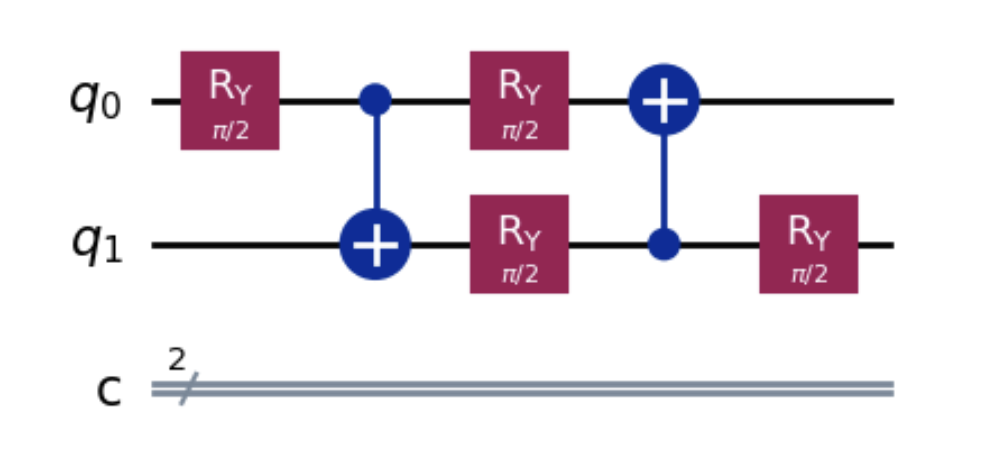

Now for $\alpha \in [0, 2\pi)$ and $\beta \in [0, 2\pi)$ do the following:

- For $\alpha$ and $\beta$ pick 20 equidistant points in the interval, i.e. total of 400 pairs of points.
- Implement the circuit above with these pairs of values.
- Calculate the average of $Z \otimes Z$ using the statistical simulation (the default `shots=1024` is fine).
- Finally, plot $\langle Z \otimes Z \rangle$, i.e. the average value of $Z \otimes Z$, against pairs $(\alpha, \beta)$ and produce a 3D plot. This can be done with `matplotlib`

## Solution

In [ ]:
%pip install qiskit qiskit-aer matplotlib pylatexenc numpy

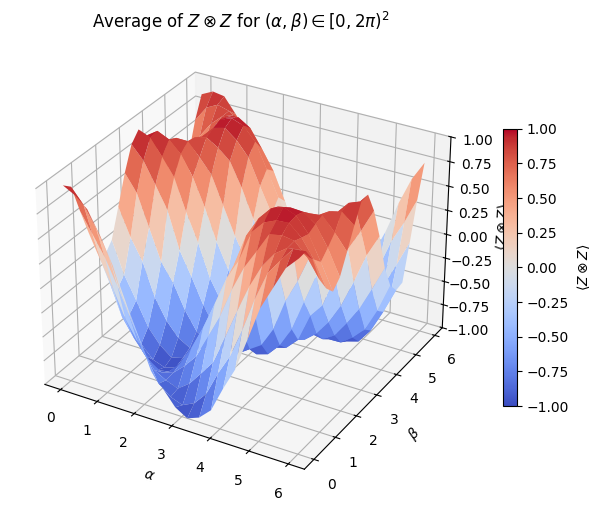

In [6]:
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
import numpy as np
import matplotlib.pyplot as plt

SHOTS = 1024
N_POINTS = 20

alphas = np.linspace(0, 2*np.pi, N_POINTS, endpoint=False)
betas  = np.linspace(0, 2*np.pi, N_POINTS, endpoint=False)

sim = AerSimulator()

# Z⊗Z eigenvalue for each measured bitstring
eigenvalue = {"00": +1, "11": +1, "01": -1, "10": -1}

zz_avg = []

for alpha in alphas:
    for beta in betas:
        qc = QuantumCircuit(2)

        qc.ry(alpha, 0)
        qc.cx(0, 1)
        qc.ry(alpha, 1)

        qc.ry(beta, 0)
        qc.cx(1, 0)
        qc.ry(beta, 1)

        qc.measure_all()

        counts = sim.run(transpile(qc, sim), shots=SHOTS).result().get_counts()

        # <Z⊗Z> = sum over outcomes of (eigenvalue * number of times observed) / shots
        zz_avg.append(
            sum(eigenvalue[bitstring] * count for bitstring, count in counts.items()) / SHOTS
            )

# Convert the list of 400 results into a 20x20 grid
zz_avg = np.array(zz_avg).reshape(len(alphas), len(betas))

# 20x20 grids holding the alpha and beta value of every cell
A, B = np.meshgrid(alphas, betas, indexing="ij")

fig = plt.figure(figsize=(8, 6))  # empty figure, 8 x 6 inches
ax = fig.add_subplot(projection="3d")  # add a 3D plotting area
surf = ax.plot_surface(A, B, zz_avg, cmap="coolwarm", vmin=-1, vmax=1)  # draw surface, color scale fixed to [-1, 1]

ax.set_xlabel(r"$\alpha$")
ax.set_ylabel(r"$\beta$")
ax.set_zlabel(r"$\langle Z \otimes Z \rangle$")
ax.set_zlim(-1, 1)
ax.set_title(r"Average of $Z \otimes Z$ for $(\alpha, \beta) \in [0, 2\pi)^2$")
fig.colorbar(surf, shrink=0.6, label=r"$\langle Z \otimes Z \rangle$")

plt.show()